<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/Aptos_2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh / Memuat Dataset APTOS 2019 ---
Using Colab cache for faster access to the 'aptos2019' dataset.
Path to dataset files: /kaggle/input/aptos2019
File CSV ditemukan: /kaggle/input/aptos2019/train_1.csv
Total gambar valid yang siap diproses: 2930
Sampel citra retina untuk Modul 1-3: /kaggle/input/aptos2019/train_images/train_images/1ae8c165fd53.png



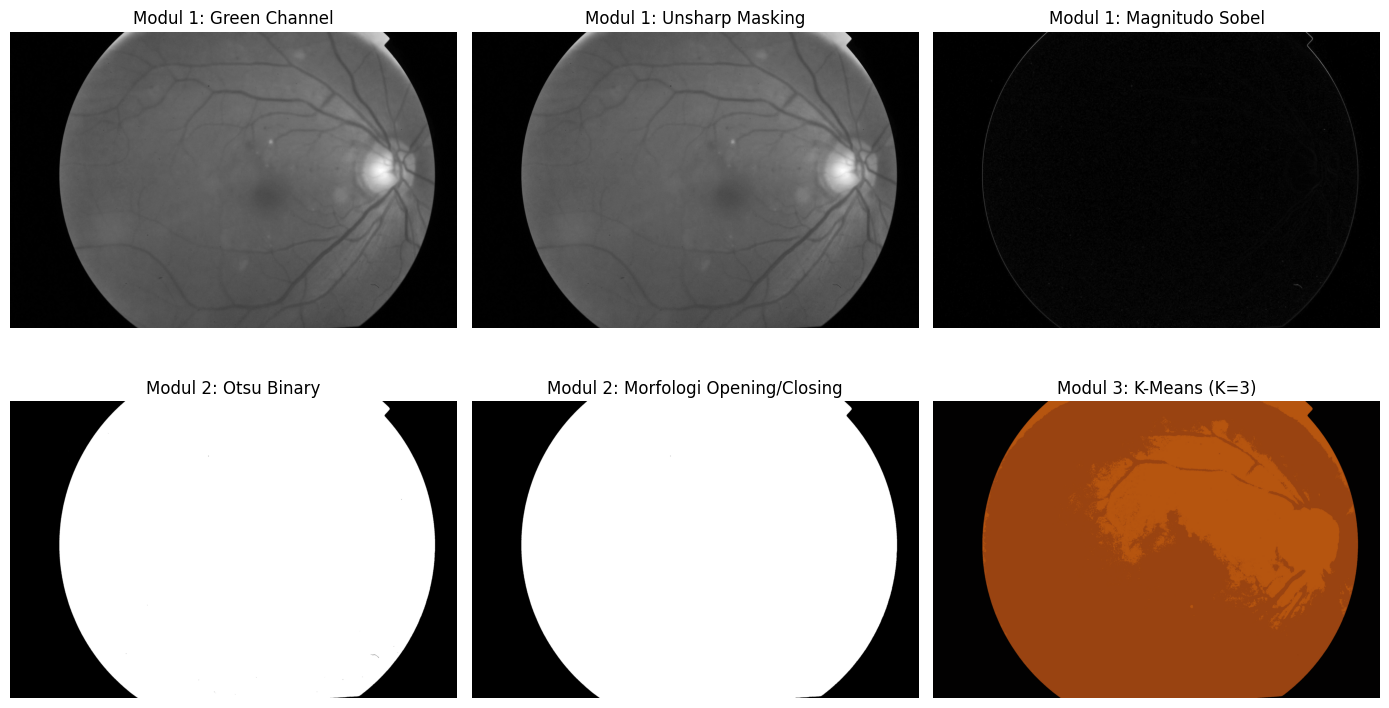


--- Modul 4: Membagi Dataset & Training EfficientNetB0 ---
Found 2344 validated image filenames belonging to 5 classes.
Found 586 validated image filenames belonging to 5 classes.
Epoch 1/3
74/74 ━━━━━━━━━━━━━━━━━━━━ 719s 9s/step - accuracy: 0.4164 - loss: 1.4736 - val_accuracy: 0.1024 - val_loss: 1.6598
Epoch 2/3
74/74 ━━━━━━━━━━━━━━━━━━━━ 660s 9s/step - accuracy: 0.4842 - loss: 1.3370 - val_accuracy: 0.1024 - val_loss: 1.6030
Epoch 3/3
74/74 ━━━━━━━━━━━━━━━━━━━━ 660s 9s/step - accuracy: 0.4829 - loss: 1.3153 - val_accuracy: 0.4898 - val_loss: 1.5160
19/19 ━━━━━━━━━━━━━━━━━━━━ 126s 6s/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

     Grade 0       0.49      1.00      0.66       287
     Grade 1       0.00      0.00      0.00        60
     Grade 2       0.00      0.00      0.00       161
     Grade 3       0.00      0.00      0.00        31
     Grade 4       0.00      0.00      0.00        47

    accuracy      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


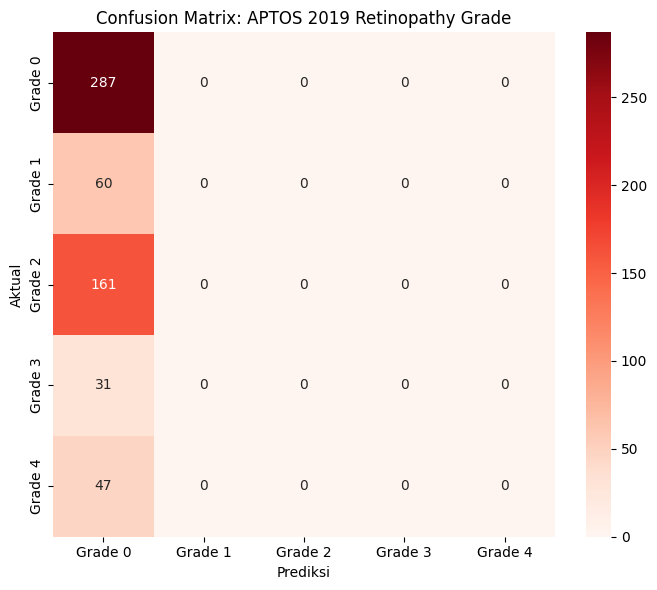

In [15]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH & DETEKSI PATH DATASET APTOS 2019
# =====================================================================
print("--- Mengunduh / Memuat Dataset APTOS 2019 ---")
path = kagglehub.dataset_download("mariaherrerot/aptos2019")
print("Path to dataset files:", path)

# 1. Cari file CSV secara fleksibel
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError(f"Tidak ditemukan file CSV di {path}")

# Cari CSV yang mengandung kata 'train'
train_csv_list = [f for f in csv_files if "train" in os.path.basename(f).lower()]
train_csv_path = train_csv_list[0] if train_csv_list else csv_files[0]
print(f"File CSV ditemukan: {train_csv_path}")

df = pd.read_csv(train_csv_path)

# 2. Cari semua file gambar (.png/.jpg/.jpeg)
image_files = glob.glob(os.path.join(path, "**", "*.png"), recursive=True)
if not image_files:
    image_files = glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
                  glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset!")

# Pemetaan ID Gambar ke Path Lengkap
image_map = {os.path.splitext(os.path.basename(f))[0]: f for f in image_files}

# Deteksi nama kolom ID dan Label pada CSV
id_col = 'id_code' if 'id_code' in df.columns else df.columns[0]
label_col = 'diagnosis' if 'diagnosis' in df.columns else df.columns[1]

# Tautkan path gambar langsung ke DataFrame
df['file_path'] = df[id_col].astype(str).map(image_map)

# Hapus baris jika gambar tidak cocok/ditemukan
df = df.dropna(subset=['file_path']).reset_index(drop=True)
df['diagnosis_str'] = df[label_col].astype(str)

print(f"Total gambar valid yang siap diproses: {len(df)}")
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra retina untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Gaussian Blur, Unsharp Masking & Sobel Exudate Edge Detection
# =====================================================================
def modul_1_processing(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    # Green channel untuk kontras optimal pembuluh darah
    green_ch = img[:, :, 1]

    # Gaussian Blur (5x5, sigma=1.0)
    blurred = cv2.GaussianBlur(green_ch, (5, 5), 1.0)

    # Unsharp Masking
    alpha = 1.5
    unsharp = cv2.addWeighted(green_ch, 1 + alpha, blurred, -alpha, 0)

    # Magnitudo Sobel Sumbu X dan Y
    sobel_x = cv2.Sobel(unsharp, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(unsharp, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_mag = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return green_ch, unsharp, sobel_mag


# =====================================================================
# MODUL 2: Otsu Thresholding & Morfologi Optic Disc (Kernel 3x3)
# =====================================================================
def modul_2_processing(unsharp_img):
    # Otsu Thresholding
    _, binary_otsu = cv2.threshold(unsharp_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Kernel Morfologi 3x3
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    # Opening diikuti Closing
    opened = cv2.morphologyEx(binary_otsu, cv2.MORPH_OPEN, kernel)
    clean_binary = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

    return binary_otsu, clean_binary


# =====================================================================
# MODUL 3: K-Means Color Segmentation (K=3, Float32)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Reshape ke float32
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # K-Means Criteria (Eps=0.2, Max Iterasi=100)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Fine-Tuning EfficientNetB0 (Unfreeze 20 Layer Terdalam)
# =====================================================================
def modul_4_train_and_eval(df, img_size=(224, 224), batch_size=32, epochs=3):
    print("\n--- Modul 4: Membagi Dataset & Training EfficientNetB0 ---")

    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['diagnosis_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='diagnosis_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='diagnosis_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = True

    # Freeze seluruh layer kecuali 20 layer terdalam
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(train_df['diagnosis_str'].unique()), activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # Evaluasi Model
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes
    class_names = [f"Grade {i}" for i in range(len(np.unique(y_true)))]

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: APTOS 2019 Retinopathy Grade')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1, 2, 3
    green_ch, unsharp_img, sobel_edges = modul_1_processing(sample_img_path)
    raw_otsu, clean_optic_disc = modul_2_processing(unsharp_img)
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Modul 1-3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(green_ch, cmap='gray')
    axes[0, 0].set_title('Modul 1: Green Channel')

    axes[0, 1].imshow(unsharp_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Unsharp Masking')

    axes[0, 2].imshow(sobel_edges, cmap='gray')
    axes[0, 2].set_title('Modul 1: Magnitudo Sobel')

    axes[1, 0].imshow(raw_otsu, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary')

    axes[1, 1].imshow(clean_optic_disc, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Opening/Closing')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4
    modul_4_train_and_eval(df, epochs=3)